In [32]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('data/law_and_order_ratings.csv')

In [7]:
df.head()

,Title,Rating,Season
0,S1.E1 ∙ Payback,8.2,1
1,S1.E2 ∙ A Single Life,8.0,1
2,S1.E3 ∙ ...Or Just Look Like One,7.7,1
3,S1.E4 ∙ Hysteria,8.1,1
4,S1.E5 ∙ Wanderlust,7.7,1


In [8]:
df['Title'][0]

'S1.E1 ∙ Payback'

In [12]:
df['Episode'] = df['Title'].str.extract(r'E(\d+)')

In [19]:
df['Season'] = df['Season'].astype(int)
df['Episode'] = df['Episode'].astype(int)

In [21]:
df = df[['Season', 'Episode', 'Title', 'Rating']]

In [22]:
df['Rating'] = df['Rating'].astype(float)

In [23]:
# Group by season and calculate the average rating
df.groupby('Season')['Rating'].mean()


Season
1     7.981818
2     8.113636
3     8.177273
4     8.236364
5     8.250000
6     8.222727
7     8.163636
8     8.109091
9     8.159091
10    8.204545
11    8.181818
12    8.054545
13    8.081818
14    8.068182
15    8.131818
16    7.895455
17    7.627273
18    7.881818
19    7.859091
20    7.863636
21    7.800000
22    7.850000
23    7.913636
24    7.809091
25    7.618182
26    7.700000
Name: Rating, dtype: float64

In [25]:
# Get the rank of each episode within a season
df['Rank'] = df.groupby('Season')['Rating'].rank(ascending=False)

In [28]:
# Sort by season and rank
df.sort_values(['Season', 'Rank'], inplace=True)

,Season,Episode,Title,Rating,Rank
20,1,21,S1.E21 ∙ Nocturne,8.6,1.0
19,1,20,S1.E20 ∙ Remorse,8.4,2.5
21,1,22,S1.E22 ∙ Slaves,8.4,2.5
6,1,7,S1.E7 ∙ Uncivilized,8.3,4.5
15,1,16,S1.E16 ∙ The Third Guy,8.3,4.5
...,...,...,...,...,...
543,25,6,S25.E6 ∙ Carousel,7.4,18.5
535,25,20,S24.E20 ∙ Debatable,7.3,20.0
531,25,16,S24.E16 ∙ The Presence of Absence,7.1,21.0
539,25,2,S25.E2 ∙ Truth Embargo,4.3,22.0


In [29]:
# Get the top 5 episodes of each season
df[df['Rank'] <= 5]

,Season,Episode,Title,Rating,Rank
20,1,21,S1.E21 ∙ Nocturne,8.6,1.0
19,1,20,S1.E20 ∙ Remorse,8.4,2.5
21,1,22,S1.E22 ∙ Slaves,8.4,2.5
6,1,7,S1.E7 ∙ Uncivilized,8.3,4.5
15,1,16,S1.E16 ∙ The Third Guy,8.3,4.5
...,...,...,...,...,...
530,25,15,S24.E15 ∙ King of the Moon,8.4,1.0
536,25,21,S24.E21 ∙ Bad Things,8.2,3.0
546,25,9,S25.E9 ∙ Children of Wolves,8.2,3.0
549,25,12,S25.E12 ∙ Marauder,8.2,3.0


In [30]:
# Sort all episode by rating
df.sort_values('Rating', ascending=False)

,Season,Episode,Title,Rating,Rank
141,7,3,S7.E3 ∙ 911,9.3,1.0
250,12,3,S12.E3 ∙ Behave,9.0,1.0
197,9,15,S9.E15 ∙ Undercover,9.0,1.0
199,10,17,S9.E17 ∙ Authority,9.0,1.0
388,18,23,S17.E23 ∙ Heartfelt Passages,9.0,1.0
...,...,...,...,...,...
421,20,12,S19.E12 ∙ Info Wars,6.2,22.0
447,21,14,S20.E14 ∙ Part 33,6.1,22.0
478,22,1,S22.E1 ∙ Guardians and Gladiators,5.9,22.0
356,17,14,S16.E14 ∙ Intimidation Game,4.6,22.0


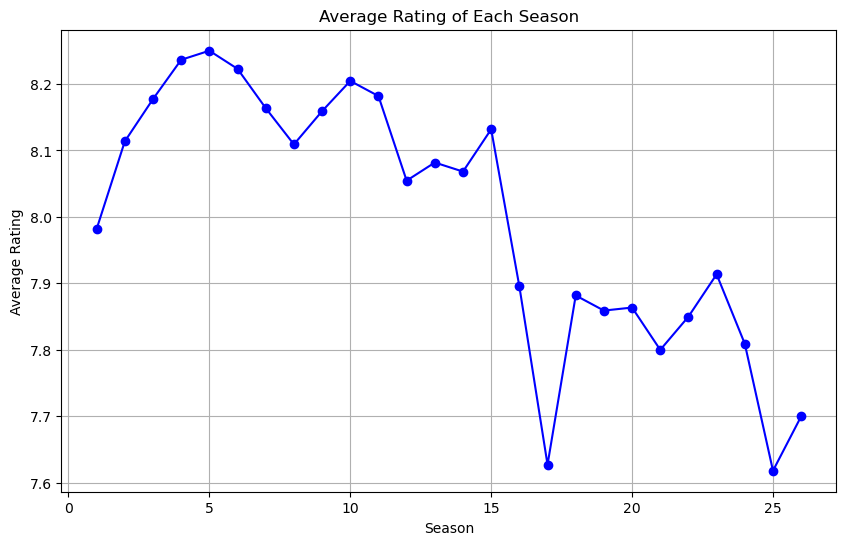

In [35]:
# Plot the average rating of each season
avg_by_season = df.groupby('Season')['Rating'].mean()
plt.figure(figsize=(10, 6))
plt.plot(avg_by_season.index, avg_by_season.values, marker='o', linestyle = '-', color='b')
plt.xlabel('Season')
plt.ylabel('Average Rating')
plt.title('Average Rating of Each Season')
plt.grid()
plt.show()

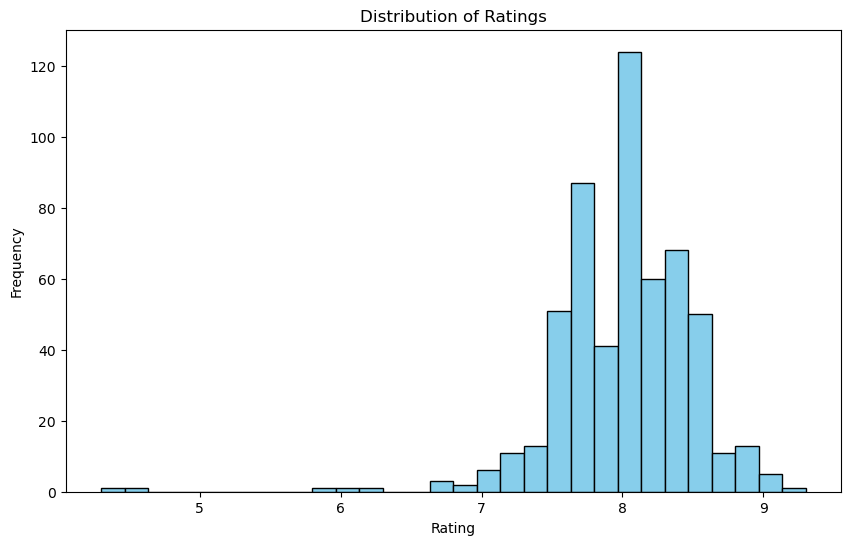

In [38]:
# Plot the distribution of ratings of all episodes
plt.figure(figsize=(10, 6))
plt.hist(df['Rating'], bins=30, color='skyblue', edgecolor='k')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Distribution of Ratings')
plt.show()